# Comparación de objetivos y retardos de generación

Este notebook compara el precio horario de REData con ESIOS 600 para España (`geo_id=3`) y evalúa objetivos agregados y retardos de generación.

La comparación se mantiene separada del Gold final. El target horario se conserva como referencia porque el optimizador necesita decidir hora por hora. El promedio entre REData y ESIOS 600 solo se considera como alternativa experimental después de medir diferencias, cobertura y backtesting.

Las observaciones de generación del intervalo objetivo no se usan como predictores contemporáneos: solo se incorporan si existe evidencia de disponibilidad `as-of`; en esta primera versión se priorizan retardos de 1 día, 1 semana y 1 año.

In [2]:
from __future__ import annotations

import importlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    sns = importlib.import_module("seaborn")
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

TZ_LOCAL = "Europe/Madrid"
ESIOS_PRICE_ID = 600
ESIOS_GENERATION_IDS = [541, 542, 546, 547, 549, 551, 552, 1297, 2041, 2051]

def find_project_root() -> Path:
    current = Path.cwd()
    for candidate in (current, *current.parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

PROJECT_ROOT = find_project_root()
REDATA_PATH = PROJECT_ROOT / "data" / "processed" / "redata" / "precios_horarios.json"
ESIOS_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "esios" / "indicadores"
print(f"Raíz: {PROJECT_ROOT}")
print(f"REData: {REDATA_PATH}")
print(f"ESIOS raw: {ESIOS_RAW_DIR}")

Raíz: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer
REData: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\processed\redata\precios_horarios.json
ESIOS raw: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\raw\esios\indicadores


## 1. Importación y configuración del entorno

Se trabaja en UTC para unir fuentes y se conserva la representación local únicamente para gráficos y calendario. La unidad de comparación será horaria.

## 2. Carga y validación de precios

REData ya está agregado a hora. ESIOS 600 se filtra a España (`geo_id=3`) y se agrega desde 15 minutos a hora mediante la media de los cuatro cuartos. Los duplicados se eliminan por indicador, timestamp y zona antes de agregar.

In [3]:
def load_redata(path: Path) -> pd.DataFrame:
    payload = json.loads(path.read_text(encoding="utf-8"))
    series = next(item for item in payload["included"] if item["attributes"]["title"] == "Precio mercado spot")
    frame = pd.DataFrame(series["attributes"]["values"])
    frame = frame.rename(columns={"value": "precio_redata_eur_mwh"})
    frame["timestamp_utc"] = pd.to_datetime(frame["datetime"], utc=True, errors="coerce")
    frame["precio_redata_eur_mwh"] = pd.to_numeric(frame["precio_redata_eur_mwh"], errors="coerce")
    frame = frame.dropna(subset=["timestamp_utc"]).drop(columns=["datetime"], errors="ignore")
    return frame[["timestamp_utc", "precio_redata_eur_mwh"]].sort_values("timestamp_utc")

def load_esios_indicator(indicator_id: int, geo_id: int | None = None) -> pd.DataFrame:
    rows = []
    for path in sorted((ESIOS_RAW_DIR / str(indicator_id)).glob(f"indicador_{indicator_id}_*.json")):
        payload = json.loads(path.read_text(encoding="utf-8"))
        indicator = payload.get("indicator", {})
        for value in indicator.get("values", []):
            rows.append({
                "indicator_id": indicator_id,
                "timestamp_utc": value.get("datetime_utc") or value.get("datetime"),
                "valor": value.get("value"),
                "geo_id": value.get("geo_id"),
                "geo_name": value.get("geo_name"),
                "source_file": path.name,
            })
    frame = pd.DataFrame(rows)
    if frame.empty:
        return frame
    frame["timestamp_utc"] = pd.to_datetime(frame["timestamp_utc"], utc=True, errors="coerce")
    frame["valor"] = pd.to_numeric(frame["valor"], errors="coerce")
    if geo_id is not None:
        frame = frame[frame["geo_id"] == geo_id].copy()
    frame = frame.dropna(subset=["timestamp_utc"])
    key = ["indicator_id", "timestamp_utc", "geo_id"]
    return frame.sort_values("source_file").drop_duplicates(key, keep="last")

redata = load_redata(REDATA_PATH)
esios_600_15m = load_esios_indicator(ESIOS_PRICE_ID, geo_id=3)
esios_600_15m = esios_600_15m.rename(columns={"valor": "precio_esios600_eur_mwh"})
esios_600_hourly = (
    esios_600_15m.set_index("timestamp_utc")["precio_esios600_eur_mwh"]
    .resample("1h")
    .mean()
    .rename("precio_esios600_eur_mwh")
    .reset_index()
)
prices = redata.merge(esios_600_hourly, on="timestamp_utc", how="inner").sort_values("timestamp_utc")
prices["diferencia_eur_mwh"] = prices["precio_redata_eur_mwh"] - prices["precio_esios600_eur_mwh"]
prices["precio_promedio_eur_mwh"] = prices[["precio_redata_eur_mwh", "precio_esios600_eur_mwh"]].mean(axis=1)
print(f"REData: {len(redata):,} filas; nulos: {redata.isna().sum().to_dict()}")
print(f"ESIOS 600 España 15m: {len(esios_600_15m):,} filas; nulos: {esios_600_15m.isna().sum().to_dict()}")
print(f"Periodo común horario: {prices['timestamp_utc'].min()} -> {prices['timestamp_utc'].max()}")

REData: 8,760 filas; nulos: {'timestamp_utc': 0, 'precio_redata_eur_mwh': 0}
ESIOS 600 España 15m: 63,455 filas; nulos: {'indicator_id': 0, 'timestamp_utc': 0, 'precio_esios600_eur_mwh': 0, 'geo_id': 0, 'geo_name': 0, 'source_file': 0}
Periodo común horario: 2025-09-30 22:00:00+00:00 -> 2026-09-30 21:00:00+00:00


In [4]:
prices["timestamp_local"] = prices["timestamp_utc"].dt.tz_convert(TZ_LOCAL)
prices["fecha_local"] = prices["timestamp_local"].dt.date
prices["hora_local"] = prices["timestamp_local"].dt.hour
prices["dia_semana"] = prices["timestamp_local"].dt.day_name()
prices["es_fin_de_semana"] = prices["timestamp_local"].dt.dayofweek >= 5
prices["es_negativo_redata"] = prices["precio_redata_eur_mwh"] < 0
prices["es_negativo_esios"] = prices["precio_esios600_eur_mwh"] < 0

hourly_target = prices.set_index("timestamp_utc")[["precio_redata_eur_mwh", "precio_esios600_eur_mwh", "precio_promedio_eur_mwh"]]
daily_targets = hourly_target.resample("1D").agg(["mean", "min", "max"])
daily_targets.columns = [f"{source}_{stat}" for source, stat in daily_targets.columns]
operating_hours = prices[prices["hora_local"].between(8, 20)].copy()
operating_targets = operating_hours.groupby("fecha_local")[["precio_redata_eur_mwh", "precio_esios600_eur_mwh", "precio_promedio_eur_mwh"]].mean().add_suffix("_media_08_20")

# Ejemplo reproducible de media ponderada; sustituir por la curva de consumo real cuando esté disponible.
consumption_weights = pd.Series(1.0, index=hourly_target.index)
weighted_target = (hourly_target.mul(consumption_weights, axis=0).resample("1D").sum().div(consumption_weights.resample("1D").sum(), axis=0))
weighted_target = weighted_target.add_suffix("_media_ponderada")
print("Objetivo horario:", hourly_target.shape)
print("Objetivos diarios:", daily_targets.shape)
print("Objetivo franja 08-20:", operating_targets.shape)

Objetivo horario: (8760, 3)
Objetivos diarios: (366, 9)
Objetivo franja 08-20: (365, 3)


C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_18692\2526872813.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  prices["es_fin_de_semana"] = prices["timestamp_local"].dt.dayofweek >= 5


In [5]:
objective_summary = pd.DataFrame({
    "objetivo": [
        "horario_redata",
        "horario_esios600",
        "horario_promedio",
        "media_diaria_redata",
        "media_08_20_redata",
        "media_ponderada_redata",
    ],
    "filas": [
        hourly_target["precio_redata_eur_mwh"].notna().sum(),
        hourly_target["precio_esios600_eur_mwh"].notna().sum(),
        hourly_target["precio_promedio_eur_mwh"].notna().sum(),
        daily_targets["precio_redata_eur_mwh_mean"].notna().sum(),
        operating_targets["precio_redata_eur_mwh_media_08_20"].notna().sum(),
        weighted_target["precio_redata_eur_mwh_media_ponderada"].notna().sum(),
    ],
    "resolucion": ["1 hora", "1 hora", "1 hora", "1 día", "franja diaria", "1 día"],
})

# Cuánto cambia una agregación respecto a la media horaria del mismo día.
daily_target_check = daily_targets[["precio_redata_eur_mwh_mean", "precio_redata_eur_mwh_min", "precio_redata_eur_mwh_max"]].copy()
daily_target_check["rango_intradia_eur_mwh"] = daily_target_check["precio_redata_eur_mwh_max"] - daily_target_check["precio_redata_eur_mwh_min"]
print("Resumen de objetivos:")
display(objective_summary)
print("Variabilidad intradía de REData:")
display(daily_target_check["rango_intradia_eur_mwh"].describe().to_frame().T)

Resumen de objetivos:


,objetivo,filas,resolucion
0,horario_redata,8760,1 hora
1,horario_esios600,8759,1 hora
2,horario_promedio,8760,1 hora
3,media_diaria_redata,366,1 día
4,media_08_20_redata,365,franja diaria
5,media_ponderada_redata,366,1 día


Variabilidad intradía de REData:


,count,mean,std,min,25%,50%,75%,max
rango_intradia_eur_mwh,366.0,115.675574,57.076308,2.2225,75.5925,108.605,146.635,279.425


## 4. Comparación gráfica de precios

Las figuras permiten comprobar si la media entre fuentes conserva el comportamiento horario y si la agregación diaria ocultaría horas negativas, baratas o caras.

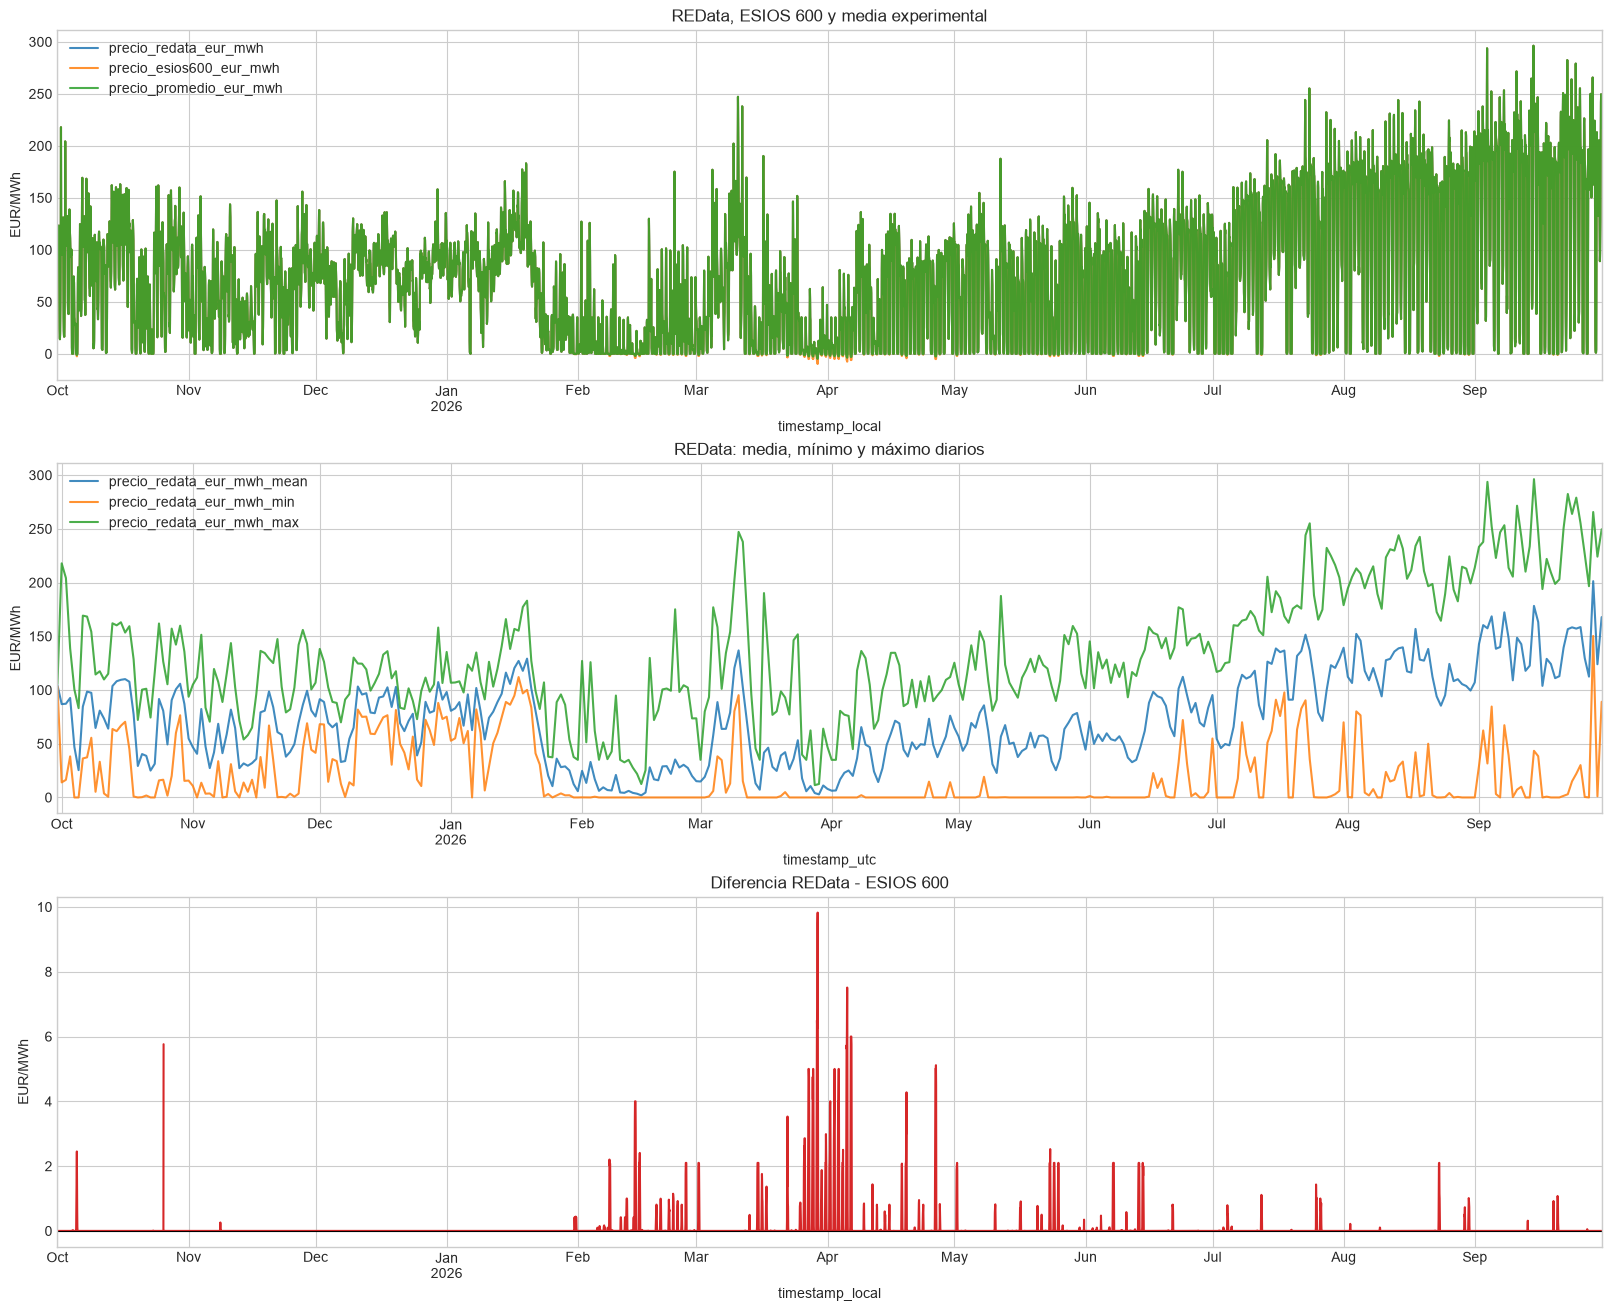

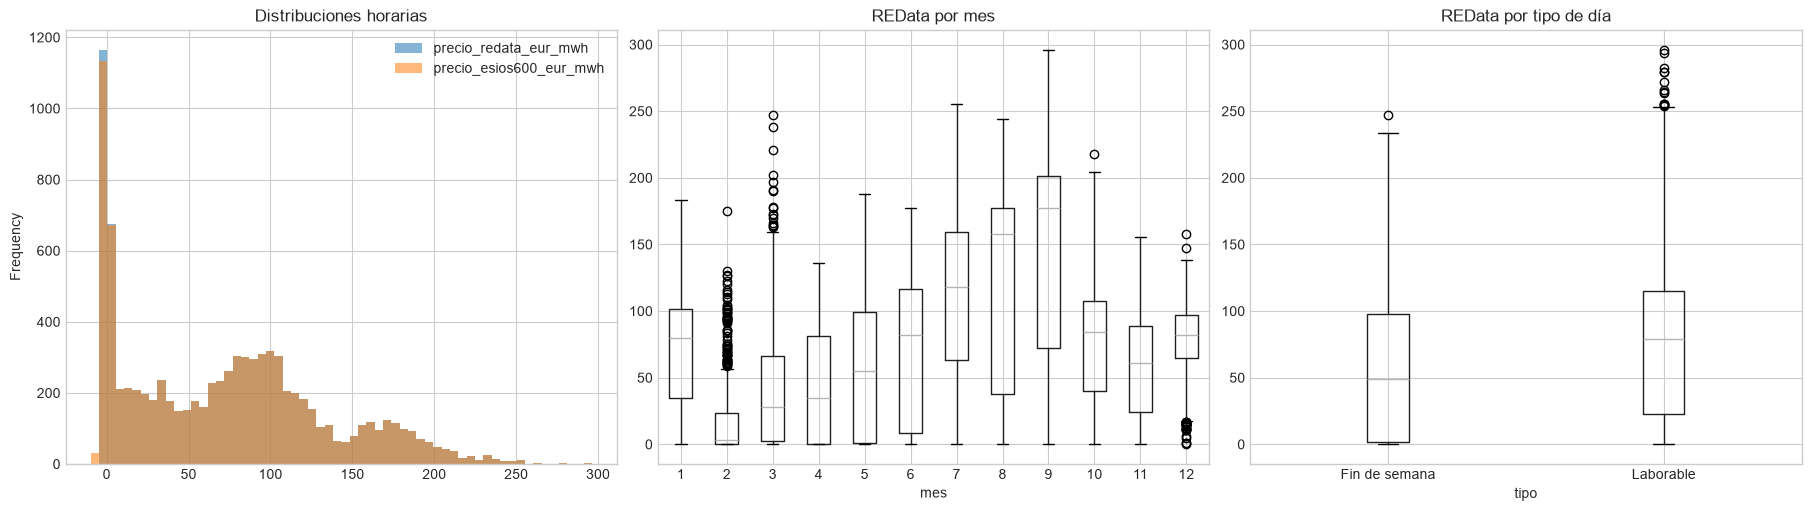

Porcentaje de horas negativas:
REData       0.00
ESIOS 600    8.77
dtype: float64


In [14]:
fig, axes = plt.subplots(3, 1, figsize=(16, 13), constrained_layout=True)
prices.set_index("timestamp_local")[["precio_redata_eur_mwh", "precio_esios600_eur_mwh", "precio_promedio_eur_mwh"]].plot(ax=axes[0], alpha=0.85)
axes[0].set_title("REData, ESIOS 600 y media experimental")
axes[0].set_ylabel("EUR/MWh")

daily_targets.filter(like="precio_redata").plot(ax=axes[1], alpha=0.85)
axes[1].set_title("REData: media, mínimo y máximo diarios")
axes[1].set_ylabel("EUR/MWh")

prices.set_index("timestamp_local")["diferencia_eur_mwh"].plot(ax=axes[2], color="tab:red")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_title("Diferencia REData - ESIOS 600")
axes[2].set_ylabel("EUR/MWh")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
prices[["precio_redata_eur_mwh", "precio_esios600_eur_mwh"]].plot.hist(bins=60, alpha=0.55, ax=axes[0])
axes[0].set_title("Distribuciones horarias")
prices.assign(mes=prices["timestamp_local"].dt.month).boxplot(column="precio_redata_eur_mwh", by="mes", ax=axes[1])
axes[1].set_title("REData por mes")
prices.assign(tipo=np.where(prices["es_fin_de_semana"], "Fin de semana", "Laborable")).boxplot(column="precio_redata_eur_mwh", by="tipo", ax=axes[2])
axes[2].set_title("REData por tipo de día")
plt.suptitle("")
plt.show()

negative_share = pd.Series({
    "REData": prices["es_negativo_redata"].mean(),
    "ESIOS 600": prices["es_negativo_esios"].mean(),
})
print("Porcentaje de horas negativas:")
print((negative_share * 100).round(2))

## 5. Creación de retardos temporales de generación

Se cargan los indicadores de generación disponibles en ESIOS. La lista es parametrizable porque la cobertura puede cambiar. Se conservan valores nulos y metadatos de disponibilidad; no se convierten huecos en cero.

In [6]:
generation_parts = []
for indicator_id in ESIOS_GENERATION_IDS:
    indicator_frame = load_esios_indicator(indicator_id, geo_id=3)
    if indicator_frame.empty:
        continue
    hourly = (
        indicator_frame.set_index("timestamp_utc")["valor"]
        .resample("1h")
        .mean()
        .rename(f"generacion_{indicator_id}")
    )
    generation_parts.append(hourly)

generation_base = pd.concat(generation_parts, axis=1).sort_index() if generation_parts else pd.DataFrame(index=prices.set_index("timestamp_utc").index)
generation_base = generation_base.loc[~generation_base.index.duplicated(keep="last")]
generation = generation_base.copy()
base_columns = list(generation_base.columns)

# Los retardos se alinean por timestamp UTC y no introducen observaciones futuras.
for lag_name, lag_hours in {"lag_1d": 24, "lag_1w": 24 * 7, "lag_1y": 24 * 365}.items():
    for column in base_columns:
        generation[f"{column}_{lag_name}"] = generation_base[column].shift(lag_hours)

print(f"Indicadores base cargados: {len(base_columns)}; total con retardos: {len(generation.columns)}")
print("Cobertura de generación:")
print(generation.notna().mean().sort_values(ascending=False).head(20).round(3))

Indicadores base cargados: 2; total con retardos: 8
Cobertura de generación:
generacion_2041           0.999
generacion_2051           0.999
generacion_2041_lag_1d    0.997
generacion_2051_lag_1d    0.997
generacion_2041_lag_1w    0.989
generacion_2051_lag_1w    0.989
generacion_2041_lag_1y    0.499
generacion_2051_lag_1y    0.499
dtype: float64


## 6. Comparación de variables con y sin retardos

Se preparan cuatro conjuntos conceptuales. El conjunto contemporáneo solo es válido cuando cada indicador tiene timestamp de publicación o disponibilidad anterior a `forecast_origin`; al no existir todavía ese contrato para todos los indicadores, se marca como diagnóstico y no como conjunto final.

In [7]:
calendar_features = pd.DataFrame(index=prices.set_index("timestamp_utc").index)
calendar_features["hora"] = calendar_features.index.tz_convert(TZ_LOCAL).hour
calendar_features["dia_semana"] = calendar_features.index.tz_convert(TZ_LOCAL).dayofweek
calendar_features["mes"] = calendar_features.index.tz_convert(TZ_LOCAL).month

price_features = prices.set_index("timestamp_utc")[["precio_redata_eur_mwh"]].copy()
price_features["precio_lag_1h"] = price_features["precio_redata_eur_mwh"].shift(1)
price_features["precio_lag_1d"] = price_features["precio_redata_eur_mwh"].shift(24)
price_features["precio_lag_1w"] = price_features["precio_redata_eur_mwh"].shift(24 * 7)

base_features = calendar_features.join(price_features)
generation_lag_features = generation.filter(regex=r"_lag_(1d|1w|1y)$")
features_with_generation_lags = base_features.join(generation_lag_features, how="left")
print("Base:", base_features.shape)
print("Con retardos de generación:", features_with_generation_lags.shape)

Base: (8760, 7)
Con retardos de generación: (8760, 13)


C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_18692\296151084.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  calendar_features["dia_semana"] = calendar_features.index.tz_convert(TZ_LOCAL).dayofweek


## 7. Análisis de correlaciones y disponibilidad temporal

Las correlaciones son descriptivas, no evidencia causal. Se comparan siempre con cobertura y antigüedad; una correlación alta de una observación futura no es utilizable en predicción.

In [8]:
target_columns = ["precio_redata_eur_mwh", "precio_esios600_eur_mwh", "precio_promedio_eur_mwh"]
correlation_input = pd.concat([prices.set_index("timestamp_utc")[target_columns], generation], axis=1)
correlations = correlation_input.corr(numeric_only=True)[target_columns].sort_values("precio_redata_eur_mwh", ascending=False)
coverage = pd.DataFrame({
    "filas": generation.shape[0],
    "no_nulos": generation.notna().sum(),
    "cobertura": generation.notna().mean(),
    "primer_timestamp": generation.apply(lambda series: series.first_valid_index()),
    "ultimo_timestamp": generation.apply(lambda series: series.last_valid_index()),
}).sort_values("cobertura", ascending=False)
print("Correlaciones más altas con REData:")
display(correlations.head(15))
print("Disponibilidad de variables de generación:")
display(coverage.head(15))

Correlaciones más altas con REData:


C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_18692\2007279412.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  correlation_input = pd.concat([prices.set_index("timestamp_utc")[target_columns], generation], axis=1)


,precio_redata_eur_mwh,precio_esios600_eur_mwh,precio_promedio_eur_mwh
precio_redata_eur_mwh,1.000000,0.999967,0.999992
precio_promedio_eur_mwh,0.999992,0.999992,1.000000
precio_esios600_eur_mwh,0.999967,1.000000,0.999992
generacion_2041,0.791114,0.790871,0.790999
generacion_2041_lag_1d,0.704697,0.704613,0.704661
generacion_2041_lag_1w,0.623929,0.623980,0.623962
generacion_2051,0.549285,0.550392,0.549843
generacion_2051_lag_1d,0.461140,0.462384,0.461724
generacion_2041_lag_1y,0.433034,0.433653,0.433351
generacion_2051_lag_1w,0.389402,0.390739,0.390073


Disponibilidad de variables de generación:


,filas,no_nulos,cobertura,primer_timestamp,ultimo_timestamp
generacion_2041,17520,17496,0.998630,2024-10-01 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2051,17520,17496,0.998630,2024-10-01 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2041_lag_1d,17520,17472,0.997260,2024-10-02 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2051_lag_1d,17520,17472,0.997260,2024-10-02 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2041_lag_1w,17520,17328,0.989041,2024-10-08 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2051_lag_1w,17520,17328,0.989041,2024-10-08 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2041_lag_1y,17520,8747,0.499258,2025-10-01 00:00:00+00:00,2026-09-30 23:00:00+00:00
generacion_2051_lag_1y,17520,8747,0.499258,2025-10-01 00:00:00+00:00,2026-09-30 23:00:00+00:00


Matriz de correlación completa:


C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_18692\3702546322.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  matrix_input = pd.concat([


,precio_redata_eur_mwh,precio_esios600_eur_mwh,precio_promedio_eur_mwh,precio_redata_eur_mwh_lag_1h,precio_redata_eur_mwh_lag_1d,precio_redata_eur_mwh_lag_1w,generacion_2041_lag_1d,generacion_2051_lag_1d,generacion_2041_lag_1w,generacion_2051_lag_1w,generacion_2041_lag_1y,generacion_2051_lag_1y
precio_redata_eur_mwh,1.00,1.00,1.00,0.95,0.89,0.79,0.70,0.46,0.62,0.39,0.43,0.31
precio_esios600_eur_mwh,1.00,1.00,1.00,0.95,0.89,0.79,0.70,0.46,0.62,0.39,0.43,0.31
precio_promedio_eur_mwh,1.00,1.00,1.00,0.95,0.89,0.79,0.70,0.46,0.62,0.39,0.43,0.31
precio_redata_eur_mwh_lag_1h,0.95,0.95,0.95,1.00,0.85,0.75,0.66,0.46,0.57,0.38,0.40,0.31
precio_redata_eur_mwh_lag_1d,0.89,0.89,0.89,0.85,1.00,0.77,0.79,0.55,0.60,0.38,0.45,0.36
precio_redata_eur_mwh_lag_1w,0.79,0.79,0.79,0.75,0.77,1.00,0.59,0.35,0.79,0.56,0.38,0.26
generacion_2041_lag_1d,0.70,0.70,0.70,0.66,0.79,0.59,1.00,0.49,0.53,0.29,0.52,0.37
generacion_2051_lag_1d,0.46,0.46,0.46,0.46,0.55,0.35,0.49,1.00,0.24,0.61,0.41,0.42
generacion_2041_lag_1w,0.62,0.62,0.62,0.57,0.60,0.79,0.53,0.24,1.00,0.49,0.41,0.27
generacion_2051_lag_1w,0.39,0.39,0.39,0.38,0.38,0.56,0.29,0.61,0.49,1.00,0.35,0.29


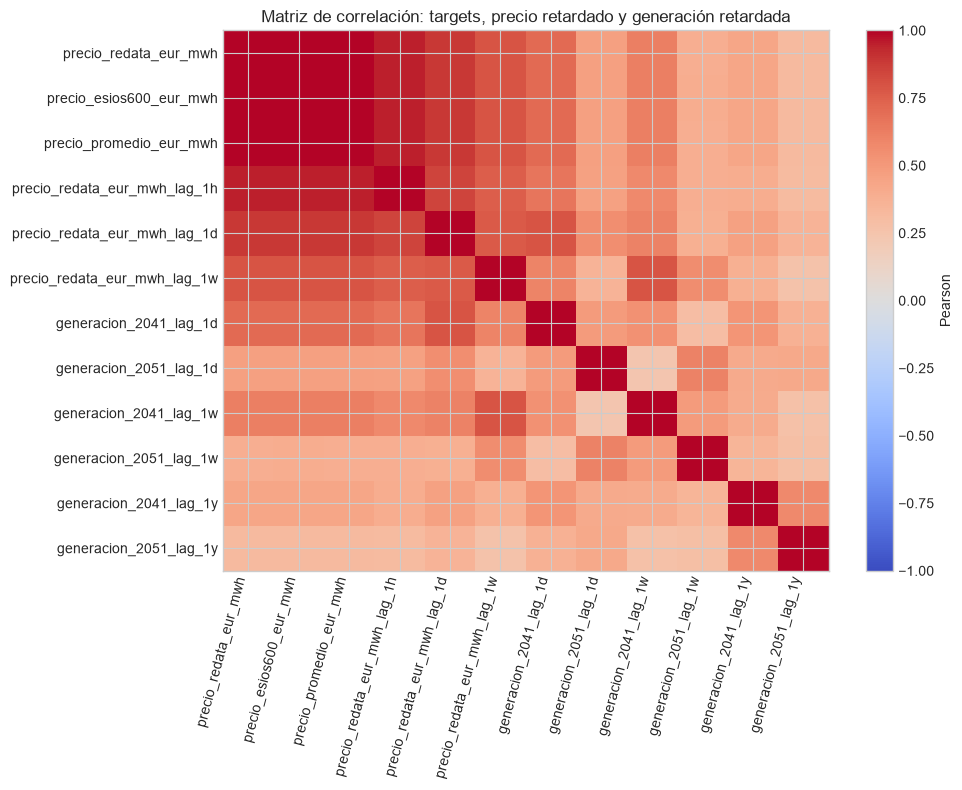

Variables ordenadas por correlación con REData:


,precio_redata_eur_mwh,precio_esios600_eur_mwh,precio_promedio_eur_mwh
precio_redata_eur_mwh,1.000,1.000,1.000
precio_promedio_eur_mwh,1.000,1.000,1.000
precio_esios600_eur_mwh,1.000,1.000,1.000
precio_redata_eur_mwh_lag_1h,0.948,0.948,0.948
precio_redata_eur_mwh_lag_1d,0.886,0.886,0.886
precio_redata_eur_mwh_lag_1w,0.790,0.790,0.790
generacion_2041_lag_1d,0.705,0.705,0.705
generacion_2041_lag_1w,0.624,0.624,0.624
generacion_2051_lag_1d,0.461,0.462,0.462
generacion_2041_lag_1y,0.433,0.434,0.433


In [9]:
matrix_columns = [
    "precio_redata_eur_mwh",
    "precio_esios600_eur_mwh",
    "precio_promedio_eur_mwh",
    "precio_redata_eur_mwh_lag_1h",
    "precio_redata_eur_mwh_lag_1d",
    "precio_redata_eur_mwh_lag_1w",
    *generation_lag_features.columns,
]
matrix_input = pd.concat([
    prices.set_index("timestamp_utc")[target_columns],
    price_features[["precio_lag_1h", "precio_lag_1d", "precio_lag_1w"]].rename(columns={
        "precio_lag_1h": "precio_redata_eur_mwh_lag_1h",
        "precio_lag_1d": "precio_redata_eur_mwh_lag_1d",
        "precio_lag_1w": "precio_redata_eur_mwh_lag_1w",
    }),
    generation_lag_features,
], axis=1)
matrix_input = matrix_input.loc[:, ~matrix_input.columns.duplicated()]
correlation_matrix = matrix_input.corr(numeric_only=True)
print("Matriz de correlación completa:")
display(correlation_matrix.round(2))

fig, ax = plt.subplots(figsize=(max(10, correlation_matrix.shape[1] * 0.65), max(8, correlation_matrix.shape[0] * 0.55)))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=75, ha="right")
ax.set_yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
ax.set_title("Matriz de correlación: targets, precio retardado y generación retardada")
fig.colorbar(image, ax=ax, label="Pearson")
fig.tight_layout()
plt.show()

# Vista compacta para seleccionar variables sin confundir correlación con disponibilidad.
target_correlation_matrix = correlation_matrix[target_columns].sort_values("precio_redata_eur_mwh", ascending=False)
print("Variables ordenadas por correlación con REData:")
display(target_correlation_matrix.round(3))

## 8. Backtesting de objetivos y variables

Se usa un corte temporal, no una partición aleatoria. El bloque final queda reservado para prueba. La comparación ejecutada en este notebook usa una referencia estacional de una semana; los modelos con y sin retardos de generación deben compararse después con el mismo protocolo.

In [19]:
def mae(actual: pd.Series, predicted: pd.Series) -> float:
    values = pd.concat([actual, predicted], axis=1).dropna()
    return float(np.mean(np.abs(values.iloc[:, 0] - values.iloc[:, 1])))

def rmse(actual: pd.Series, predicted: pd.Series) -> float:
    values = pd.concat([actual, predicted], axis=1).dropna()
    return float(np.sqrt(np.mean((values.iloc[:, 0] - values.iloc[:, 1]) ** 2)))

def split_period(index: pd.DatetimeIndex) -> tuple[pd.Timestamp, pd.Timestamp, pd.Timestamp]:
    start, end = index.min(), index.max()
    span = end - start
    return start + span * 0.60, start + span * 0.80, end

model_frame = prices.set_index("timestamp_utc").join(features_with_generation_lags, how="left", rsuffix="_feature")
model_frame["target_lag_1w"] = model_frame["precio_redata_eur_mwh"].shift(24 * 7)
train_end, validation_end, test_end = split_period(model_frame.index)
model_frame["prediccion_naive_1w"] = model_frame["target_lag_1w"]

backtest_rows = []
for target_name in ["precio_redata_eur_mwh", "precio_esios600_eur_mwh", "precio_promedio_eur_mwh"]:
    test_mask = model_frame.index > validation_end
    actual = model_frame.loc[test_mask, target_name]
    predicted = model_frame.loc[test_mask, "prediccion_naive_1w"]
    backtest_rows.append({
        "target": target_name,
        "modelo": "naive_lag_1w",
        "periodo": "test",
        "n": int(pd.concat([actual, predicted], axis=1).dropna().shape[0]),
        "mae": mae(actual, predicted),
        "rmse": rmse(actual, predicted),
    })
backtest_metrics = pd.DataFrame(backtest_rows)
display(backtest_metrics)

C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_27896\1772323688.py:14: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  model_frame = prices.set_index("timestamp_utc").join(features_with_generation_lags, how="left", rsuffix="_feature")


,target,modelo,periodo,n,mae,rmse
0,precio_redata_eur_mwh,naive_lag_1w,test,1752,27.332256,39.415364
1,precio_esios600_eur_mwh,naive_lag_1w,test,1752,27.353888,39.416200
2,precio_promedio_eur_mwh,naive_lag_1w,test,1752,27.343072,39.415712


## 9. Comparación de métricas

Se reportan métricas de acuerdo entre fuentes y de predicción. Los errores se separan por horas negativas, baratas y caras. Las categorías se calculan sobre REData y no eliminan valores extremos válidos.

In [20]:
source_metrics = pd.DataFrame({
    "n": [len(prices)],
    "fecha_inicio": [prices["timestamp_utc"].min()],
    "fecha_fin": [prices["timestamp_utc"].max()],
    "correlacion": [prices["precio_redata_eur_mwh"].corr(prices["precio_esios600_eur_mwh"])],
    "sesgo_redata_menos_esios": [prices["diferencia_eur_mwh"].mean()],
    "mae": [mae(prices["precio_redata_eur_mwh"], prices["precio_esios600_eur_mwh"])],
    "rmse": [rmse(prices["precio_redata_eur_mwh"], prices["precio_esios600_eur_mwh"])],
    "max_error_abs": [prices["diferencia_eur_mwh"].abs().max()],
    "pct_abs_error_le_0_01": [(prices["diferencia_eur_mwh"].abs() <= 0.01).mean()],
    "pct_abs_error_le_1": [(prices["diferencia_eur_mwh"].abs() <= 1.0).mean()],
})

prices["categoria_redata"] = pd.cut(
    prices["precio_redata_eur_mwh"],
    bins=[-np.inf, 0, 50, 100, np.inf],
    labels=["negativo", "barato", "medio", "caro"],
    right=False,
)
category_metrics = prices.groupby("categoria_redata", observed=True).apply(
    lambda group: pd.Series({
        "n": len(group),
        "mae_fuentes": mae(group["precio_redata_eur_mwh"], group["precio_esios600_eur_mwh"]),
        "sesgo_fuentes": group["diferencia_eur_mwh"].mean(),
    }),
    include_groups=False,
)
print("Comparación REData vs ESIOS 600:")
display(source_metrics)
print("Error por categoría de precio REData:")
display(category_metrics)

Comparación REData vs ESIOS 600:


,n,fecha_inicio,fecha_fin,correlacion,sesgo_redata_menos_esios,mae,rmse,max_error_abs,pct_abs_error_le_0_01,pct_abs_error_le_1
0,8760,2025-09-30 22:00:00+00:00,2026-09-30 21:00:00+00:00,0.999967,0.085726,0.085726,0.513471,9.825,0.931393,0.974886


Error por categoría de precio REData:


,n,mae_fuentes,sesgo_fuentes
categoria_redata,,,
barato,3519.0,2.117391e-01,2.117391e-01
medio,2497.0,2.308694e-03,2.308694e-03
caro,2744.0,5.287639e-15,2.589441e-17


## 10. Visualización de resultados y selección del enfoque

La decisión debe basarse en el backtest y en el coste real de programar consumo, no solo en la similitud entre dos fuentes. Si el optimizador decide hora por hora, una media diaria no puede sustituir al target horario; la media REData/ESIOS se guarda únicamente como alternativa experimental.

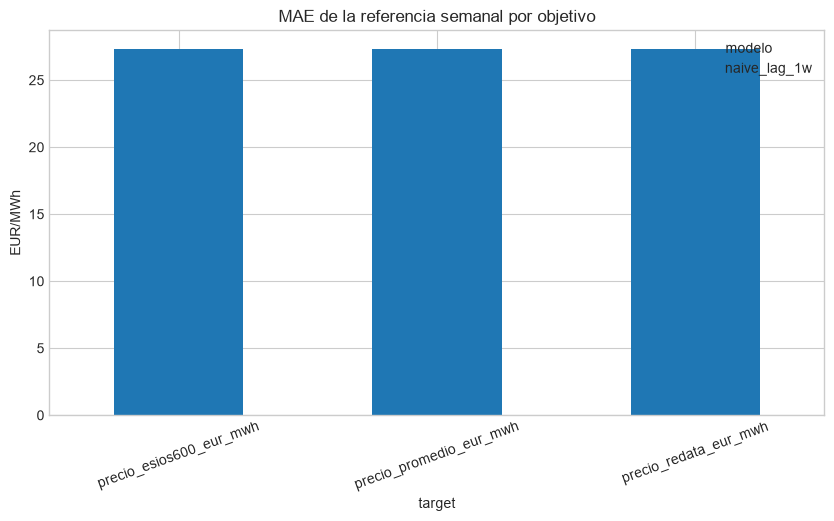

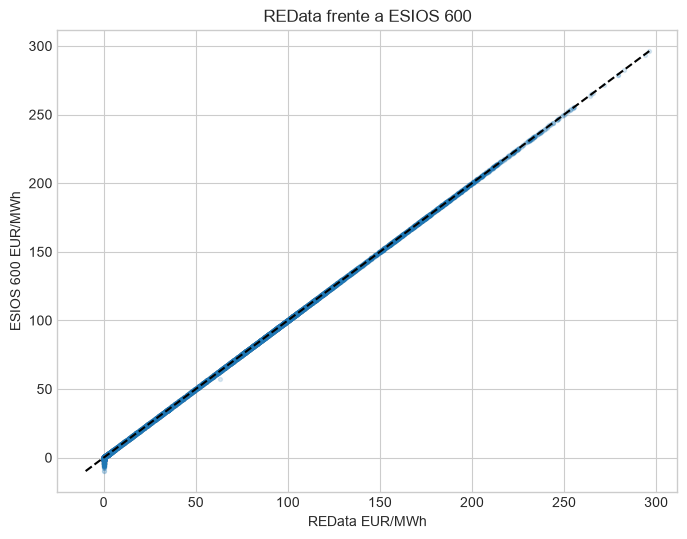

Coste real de programar 30 MWh/día usando cada señal:


,count,mean,median,sum
prediccion,,,,
precio_esios600_eur_mwh,365,642.901582,52.995,234659.0775
precio_promedio_eur_mwh,365,642.901582,52.995,234659.0775
precio_redata_eur_mwh,365,642.901582,52.995,234659.0775


Resultados guardados en: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\processed\comparacion_objetivos_generacion
Recomendación: Las fuentes están muy alineadas; mantener REData como target canónico y conservar ESIOS 600 como validación. Probar el promedio solo como experimento de backtest.


In [21]:
metric_plot = backtest_metrics.pivot(index="target", columns="modelo", values="mae")
metric_plot.plot(kind="bar", figsize=(10, 5), title="MAE de la referencia semanal por objetivo")
plt.ylabel("EUR/MWh")
plt.xticks(rotation=20)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(prices["precio_redata_eur_mwh"], prices["precio_esios600_eur_mwh"], alpha=0.15, s=8)
minimum = prices[["precio_redata_eur_mwh", "precio_esios600_eur_mwh"]].min().min()
maximum = prices[["precio_redata_eur_mwh", "precio_esios600_eur_mwh"]].max().max()
ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="black")
ax.set_xlabel("REData EUR/MWh")
ax.set_ylabel("ESIOS 600 EUR/MWh")
ax.set_title("REData frente a ESIOS 600")
plt.show()

def schedule_cost(prediction_column: str, actual_column: str = "precio_redata_eur_mwh", energy_mwh: float = 30.0, max_hourly_mwh: float = 7.0) -> pd.Series:
    rows = []
    frame = prices.set_index("timestamp_utc")
    for date, group in frame.groupby(frame["timestamp_local"].dt.date):
        ranked = group.dropna(subset=[prediction_column, actual_column]).sort_values(prediction_column)
        remaining = energy_mwh
        cost = 0.0
        for _, row in ranked.iterrows():
            volume = min(max_hourly_mwh, remaining)
            cost += volume * row[actual_column]
            remaining -= volume
            if remaining <= 0:
                break
        rows.append({"fecha": date, "prediccion": prediction_column, "coste_real_eur": cost, "energia_no_programada_mwh": max(remaining, 0)})
    return pd.DataFrame(rows)

schedule_results = pd.concat([
    schedule_cost("precio_redata_eur_mwh"),
    schedule_cost("precio_esios600_eur_mwh"),
    schedule_cost("precio_promedio_eur_mwh"),
], ignore_index=True)
print("Coste real de programar 30 MWh/día usando cada señal:")
display(schedule_results.groupby("prediccion")["coste_real_eur"].agg(["count", "mean", "median", "sum"]))

output_dir = PROJECT_ROOT / "data" / "processed" / "comparacion_objetivos_generacion"
output_dir.mkdir(parents=True, exist_ok=True)
prices.drop(columns=["timestamp_local"], errors="ignore").to_csv(output_dir / "precios_comparados_horarios.csv", index=False)
source_metrics.to_csv(output_dir / "metricas_fuentes.csv", index=False)
backtest_metrics.to_csv(output_dir / "metricas_backtest.csv", index=False)
coverage.to_csv(output_dir / "disponibilidad_generacion.csv")
print(f"Resultados guardados en: {output_dir}")

if source_metrics.loc[0, "mae"] <= 1.0 and source_metrics.loc[0, "pct_abs_error_le_1"] >= 0.95:
    recommendation = "Las fuentes están muy alineadas; mantener REData como target canónico y conservar ESIOS 600 como validación. Probar el promedio solo como experimento de backtest."
else:
    recommendation = "Las fuentes no son intercambiables sin análisis adicional; mantener REData como target canónico y no promediar automáticamente."
print("Recomendación:", recommendation)

## Observaciones para el equipo

### Resultado de la comparación de precios

- REData y ESIOS 600 están muy alineados en el periodo común: correlación aproximada de `0.999967`, MAE de `0.086 EUR/MWh` y RMSE de `0.513 EUR/MWh`.
- El `97.5%` de las diferencias absolutas son inferiores a `1 EUR/MWh`, pero existe un error máximo cercano a `9.8 EUR/MWh`. Por tanto, las fuentes son consistentes, aunque no idénticas en todas las horas.
- ESIOS 600 debe mantenerse como validación independiente y posible respaldo de calidad. REData se mantiene como target horario canónico.
- No se recomienda crear un target promedio por defecto. El promedio es una variable sintética y puede suavizar diferencias relevantes en horas baratas, caras o negativas. Solo debe compararse como alternativa dentro del backtest.

### Resultado sobre los objetivos

- El optimizador necesita un target horario porque decide cuándo consumir.
- Las medias diarias y de franja son útiles para análisis, pero no sustituyen al target horario.
- El rango intradía medio observado en REData es aproximadamente `115.7 EUR/MWh`, por lo que una agregación diaria perdería información operativa.
- La media ponderada incluida es provisional: actualmente utiliza pesos iguales. Debe sustituirse por la curva real de consumo antes de usarla para decisiones.

### Resultado sobre generación y retardos

- La matriz de correlación muestra que los retardos de precio tienen una relación fuerte con el target, especialmente `lag_1h`, `lag_1d` y `lag_1w`.
- Los retardos de generación pueden aportar información, pero la correlación no demuestra mejora predictiva ni disponibilidad operacional.
- En esta ejecución solo se encontraron dos indicadores de generación con cobertura suficiente (`2041` y `2051`). Hay que confirmar con el equipo si representan las tecnologías necesarias o ampliar el inventario.
- Se priorizan `lag_1d` y `lag_1w`. El `lag_1y` queda como experimento porque su cobertura actual es aproximadamente del 50%.

### Decisión provisional

1. Target principal: `precio_redata_eur_mwh` horario.
2. ESIOS 600: validación, control de calidad y posible fallback.
3. Media REData/ESIOS: solo candidato experimental de backtest.
4. Generación: comparar baseline sin generación frente a retardos `lag_1d` y `lag_1w`.
5. No utilizar valores contemporáneos del intervalo objetivo salvo que exista evidencia de disponibilidad anterior a `forecast_origin`.

### Pendientes antes del Gold predictivo

- Definir `forecast_origin` y los timestamps reales de publicación/disponibilidad.
- Ejecutar un backtest con los mismos cortes temporales para cada conjunto de variables.
- Evaluar MAE, RMSE y coste real de la programación, no solo correlaciones.
- Sustituir los pesos iguales por la curva de consumo real.
- Documentar qué indicadores ESIOS de generación corresponden a cada tecnología y qué cobertura histórica tienen.

## 3. Construcción de objetivos horarios y agregados

Se conserva el target horario para el optimizador. Se calculan versiones diarias y de la franja operativa 08:00-20:00 solo para estudiar cuánto se pierde al agregar. La media ponderada por consumo usa la carga flexible del caso y no sustituye al target horario.